In [1]:
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def generate_output_paths(base_paths, tensor_dirs):
    results = {}
    
    # 1. Standard SD35 Paths
    # Pattern: standard_path + tensor_dir
    # Note: Standard SD35 only has 7 directories (missing closeby_far and sitting_running_standing)
    standard_dirs = [td for td in tensor_dirs if td not in ['closeby_far', 'sitting_running_standing']]
    results['standard'] = [
        os.path.join(base_paths['standard'], td) 
        for td in standard_dirs
    ]
    
    # 2. Custom CLIC Paths
    # Pattern: redcaps_path + tensor_dir
    results['custom_clic'] = [
        os.path.join(base_paths['redcaps'], td) 
        for td in tensor_dirs
    ]
    
    # 3. CogVLM Paths
    # Pattern: cogvlm_path + tensor_dir
    results['cogvlm'] = [
        os.path.join(base_paths['cogvlm'], td) 
        for td in tensor_dirs
    ]
    
    return results

# Usage
SD_MODEL_PATHS = {
    "standard": "./x5.5-prompts_sd35_output/standard_sd35_output/",
    "redcaps": "./z0-custom_sd35_clic/custom_sd35_output/",
    "cogvlm": "./z4-cogvlm_custom_sd35/cogvlm_sd35_output/"
}

TENSOR_DIRS = [
    'behind_on_front', 'between_inside_outside', 'holding_touching_not',
    'not_without', 'top', 'below_over_under', 'closeby_far',
    'left_right_above', 'sitting_running_standing'
]

paths = generate_output_paths(SD_MODEL_PATHS, TENSOR_DIRS)

In [3]:
# Accessing them:
sd35_output_dirs = paths['standard']
custom_clic_output_dirs = paths['custom_clic']
cogvlm_output_dirs = paths['cogvlm']

In [4]:
class_pairs = pd.read_csv("./x5.5-prompts_sd35_output/class_pairs_from_143851.csv", header=None).values
class_pairs = [(row[0], row[1]) for row in class_pairs]

In [5]:
# Function to load all metadata CSVs from the output directories
def load_all_metadata(dirs):
    all_metadata = []
    for dir_path in dirs:
        if not os.path.exists(dir_path):
            print(f"Warning: Directory {dir_path} not found, skipping...")
            continue
            
        for file in os.listdir(dir_path):
            if file.startswith("metadata_") and file.endswith(".csv"):
                file_path = os.path.join(dir_path, file)
                try:
                    df = pd.read_csv(file_path)
                    # Add the output directory to each row for later reference
                    df['output_dir'] = dir_path
                    all_metadata.append(df)
                except Exception as e:
                    print(f"Error loading {file_path}: {e}")
    
    if not all_metadata:
        raise ValueError("No metadata files found!")
        
    return pd.concat(all_metadata, ignore_index=True)


In [6]:
def get_image_from_tensor(output_dir, tensor_file, tensor_index):
    tensor_path = os.path.join(output_dir, "tensors", tensor_file)
    try:
        tensor_data = torch.load(tensor_path)
        img_tensor = tensor_data['images'][tensor_index]
        # Convert tensor to numpy array for display
        img_array = img_tensor.permute(1, 2, 0).numpy()
        # Clip values to valid range
        img_array = np.clip(img_array, 0, 1)
        return img_array
    except Exception as e:
        print(f"Error loading image from {tensor_path} at index {tensor_index}: {e}")
        return None


In [7]:
def visualize_by_classes(df, class1, class2, n=10, start_idx=0):
    """Visualize images for specific class1 and class2 combination, one by one without interaction"""
    # Filter for the exact class1 and class2 in that order
    class_df = df[(df['class1'] == class1) & (df['class2'] == class2)]
    
    if len(class_df) == 0:
        print(f"No images found for class combination: '{class1}' and '{class2}'")
        return
    
    print(f"\nClass Combination: '{class1}' and '{class2}' ({len(class_df)} images found)")
    
    count = 1
    for i, (_, row) in enumerate(class_df.iterrows()):
        if i < start_idx:
            continue

        plt.figure(figsize=(8, 6))

        img = get_image_from_tensor(row['output_dir'], row['tensor_file'], row['tensor_index'])
        print(f"Tensor file: {row['tensor_file']}, Index: {row['tensor_index']}")
        if img is not None:
            # Display image
            plt.imshow(img)
            plt.axis('off')
            
            # Add detailed title with all information
            plt.title(f"Image {i+1}/{len(class_df)} | Tensor Index: {row['tensor_index']}\n"
                     f"Classes: {row['class1']} and {row['class2']}\n"
                     f"Phrase: '{row['phrase']}'\n"
                     f"Prompt: '{row['prompt']}'", 
                     fontsize=10, wrap=True)
            
            plt.tight_layout()
            plt.show()
            count += 1
        else:
            print(f"Could not load image {i+1}/{len(class_df)}")
        
        if count > n:  # Limit to first n images for this class combination
            break


In [8]:
def visualize_by_phrase(df, phrase_text, n=10, start_idx=0):
    """Visualize n image for a specific phrase"""
    # Filter for the exact phrase
    phrase_df = df[df['phrase'] == phrase_text]
    
    if len(phrase_df) == 0:
        print(f"No images found for phrase: '{phrase_text}'")
        return
    
    print(f"\nPhrase: '{phrase_text}' ({len(phrase_df)} images found)")
    count = 1
    for i, (_, row) in enumerate(phrase_df.iterrows()):
        if i < start_idx:
            continue
        
        plt.figure(figsize=(8, 6))
        img = get_image_from_tensor(row['output_dir'], row['tensor_file'], row['tensor_index'])
        print(f"Tensor file: {row['tensor_file']}, Index: {row['tensor_index']}")
        if img is not None:
            plt.imshow(img)
            plt.axis('off')
            
            # Add detailed title with all information
            plt.title(f"Image {i+1}/{len(phrase_df)} | Tensor Index: {row['tensor_index']}\n"
                     f"Phrase: '{row['phrase']}'\n"
                     f"Classes: {row['class1']} and {row['class2']}\n"
                     f"Prompt: '{row['prompt']}'", 
                     fontsize=10, wrap=True)
            
            plt.tight_layout()
            plt.show()
            count += 1
        else:
            print(f"Could not load image {i+1}/{len(phrase_df)}")
        if count > n:
            break


In [ ]:
# sd35_output_dirs = paths['standard']
# custom_clic_output_dirs = paths['custom_clic']
# cogvlm_output_dirs = paths['cogvlm']
df = load_all_metadata(sd35_output_dirs)
visualize_by_phrase(df, "above", n=100)

In [10]:
def visualize_comparison_side_by_side(df, phrase_text, custom_dirs, baseline_dirs, n=10, start_idx=0):
    """
    Displays images side-by-side with a human-readable "Photo X" counter.
    """
    phrase_df = df[df['phrase'] == phrase_text]
    
    if len(phrase_df) == 0:
        print(f"No images found for phrase: '{phrase_text}'")
        return

    grouped = phrase_df.groupby('prompt')
    print(f"\n--- Comparing Phrase: '{phrase_text}' ---")
    
    photo_counter = 1

    for prompt, group in grouped:
        if photo_counter > n:  # <-- ADD THIS
            break

        custom_rows = group[group['output_dir'].isin(custom_dirs)]
        baseline_rows = group[group['output_dir'].isin(baseline_dirs)]
        
        num_comparisons = max(len(custom_rows), len(baseline_rows))
        
        for i in range(num_comparisons):
            if i < start_idx:
                continue
                
            fig, axes = plt.subplots(1, 2, figsize=(14, 7))
            
            # --- Plot Custom Image (Left) ---
            if i < len(custom_rows):
                row = custom_rows.iloc[i]
                img = get_image_from_tensor(row['output_dir'], row['tensor_file'], row['tensor_index'])
                if img is not None:
                    axes[0].imshow(img)
                    axes[0].set_title(f"CUSTOM (Photo {photo_counter}) | Idx: {row['tensor_index']}\n{row['class1']} {phrase_text} {row['class2']}", 
                                     fontsize=11, color='royalblue', fontweight='bold')
            else:
                axes[0].text(0.5, 0.5, 'No Custom Image', ha='center', va='center')
            axes[0].axis('off')

            # --- Plot Baseline Image (Right) ---
            if i < len(baseline_rows):
                row = baseline_rows.iloc[i]
                img = get_image_from_tensor(row['output_dir'], row['tensor_file'], row['tensor_index'])
                if img is not None:
                    axes[1].imshow(img)
                    axes[1].set_title(f"BASELINE (Photo {photo_counter}) | Idx: {row['tensor_index']}\n{row['class1']} {phrase_text} {row['class2']}", 
                                     fontsize=11, color='forestgreen', fontweight='bold')
            else:
                axes[1].text(0.5, 0.5, 'No Baseline Image', ha='center', va='center')
            axes[1].axis('off')

            plt.suptitle(f"Comparison {photo_counter} | Prompt: \"{prompt}\"", fontsize=13, y=1.02)
            plt.tight_layout()
            plt.show()
            
            photo_counter += 1
            if photo_counter > n:
                break

In [11]:
# # 1. Load metadata from BOTH sets
# two_dirs = cogvlm_output_dirs + sd35_output_dirs
# df_two = load_all_metadata(two_dirs)

# # 2. Compare side-by-side (CLIC on left, standard SD on right)
# visualize_comparison_side_by_side(
#     df_two,
#     phrase_text="to the right of",            
#     custom_dirs=cogvlm_output_dirs,        
#     baseline_dirs=sd35_output_dirs,         
#     n=10
# )

In [12]:
def visualize_comparison_three_way(df, phrase_text, redcaps_dirs, baseline_dirs, cogvlm_dirs, n=5, start_idx=0):
    """
    Displays images from three models side-by-side, aligning them by prompt 
    even if tensor indices differ.
    """
    # 1. Filter for the specific phrase
    phrase_df = df[df['phrase'] == phrase_text].copy()
    
    if phrase_df.empty:
        print(f"No images found for phrase: '{phrase_text}'")
        return

    # 2. Group by prompt to ensure we are comparing the same text descriptions
    grouped = phrase_df.groupby('prompt')
    print(f"\n--- Three-Way Comparison: '{phrase_text}' ---")
    
    photo_counter = 1

    for prompt, group in grouped:
        if photo_counter > n:
            break

        # 3. Filter and SORT each model's rows to ensure alignment
        # We sort by tensor_index (or any ID) so that 'iloc[i]' matches across models
        b_rows = group[group['output_dir'].isin(baseline_dirs)].sort_values('tensor_index')
        r_rows = group[group['output_dir'].isin(redcaps_dirs)].sort_values('tensor_index')
        c_rows = group[group['output_dir'].isin(cogvlm_dirs)].sort_values('tensor_index')
        
        # Find the max number of variations available for this specific prompt
        num_comparisons = max(len(b_rows), len(r_rows), len(c_rows))
        
        for i in range(num_comparisons):
            # Skip if we haven't reached the requested start index for this prompt
            if i < start_idx:
                continue
                
            fig, axes = plt.subplots(1, 3, figsize=(20, 7))
            
            # Map models to their data and display settings
            # This avoids repetitive code and fixed the variable naming collision
            comparison_set = [
                (b_rows, "BASELINE", "forestgreen"),
                (r_rows, "RedCaps CLIC", "darkorange"),
                (c_rows, "COGVLM", "royalblue")
            ]

            for idx, (model_df, label, color) in enumerate(comparison_set):
                if i < len(model_df):
                    row = model_df.iloc[i]
                    img = get_image_from_tensor(row['output_dir'], row['tensor_file'], row['tensor_index'])
                    
                    if img is not None:
                        axes[idx].imshow(img)
                        # Displaying individual tensor indices since they can be different
                        axes[idx].set_title(
                            f"{label}\nIdx: {row['tensor_index']}\n{row['class1']} {phrase_text} {row['class2']}", 
                            fontsize=10, color=color, fontweight='bold'
                        )
                else:
                    axes[idx].text(0.5, 0.5, f'Missing {label}\nVariation {i}', ha='center', va='center')
                
                axes[idx].axis('off')

            plt.suptitle(f"Comparison {photo_counter} | Prompt: \"{prompt}\"", fontsize=14, y=1.05)
            plt.tight_layout()
            plt.show()
            
            photo_counter += 1
            if photo_counter > n:
                break

In [13]:
# # 1. Load metadata from BOTH sets
# all_dirs = cogvlm_output_dirs + sd35_output_dirs + custom_clic_output_dirs
# df_full = load_all_metadata(all_dirs)

# # 2. Compare side-by-side (CLIC on left, standard SD on right)
# visualize_comparison_three_way(
#     df_full,
#     phrase_text="above",           
#     baseline_dirs=sd35_output_dirs,         
#     redcaps_dirs=custom_clic_output_dirs,        
#     cogvlm_dirs=cogvlm_output_dirs,              
#     n=1
# )

In [14]:
# Run this cell to explore available phrases and class combinations, then visualize images

# Load data once
try:
    df_viz = load_all_metadata(sd35_output_dirs)
    print(f"\nTotal images loaded: {len(df_viz)}")
    
    # Show available phrases
    phrases = sorted(df_viz['phrase'].unique())
    print(f"\nAvailable Phrases ({len(phrases)} total): ", phrases)

    # Show available class combinations
    class_combos = df_viz.groupby(['class1', 'class2']).size().reset_index(name='count')
    print(f"\nAvailable Class Combinations ({len(class_combos)} total):")
    for i, (_, row) in enumerate(class_combos.iterrows(), 1):
        print(f"  {i}. '{row['class1']}' and '{row['class2']}' ({row['count']} images)")
    
except Exception as e:
    print(f"ERROR loading metadata: {e}")
    print("\nMake sure the directories exist:")
    for d in sd35_output_dirs:
        print(f"  - {d}")



Total images loaded: 1900

Available Phrases (19 total):  ['above', 'and not', 'behind', 'below', 'between', 'holding', 'in front of', 'inside', 'not holding', 'not touching', 'on', 'on top of', 'outside', 'over', 'to the left of', 'to the right of', 'touching', 'under', 'without']

Available Class Combinations (100 total):
  1. 'backpack' and 'wine glass' (19 images)
  2. 'banana' and 'fork' (19 images)
  3. 'banana' and 'stop sign' (19 images)
  4. 'baseball bat' and 'boat' (19 images)
  5. 'baseball bat' and 'dog' (19 images)
  6. 'baseball bat' and 'sandwich' (19 images)
  7. 'baseball glove' and 'bicycle' (19 images)
  8. 'baseball glove' and 'sandwich' (19 images)
  9. 'bear' and 'pizza' (19 images)
  10. 'bed' and 'book' (19 images)
  11. 'bench' and 'cow' (19 images)
  12. 'bench' and 'motorcycle' (19 images)
  13. 'bicycle' and 'bus' (19 images)
  14. 'book' and 'dog' (19 images)
  15. 'book' and 'sports ball' (19 images)
  16. 'book' and 'tie' (19 images)
  17. 'bowl' and 'b

Visualizing: class1='banana' and class2='fork'
✓ Found 19 images


Class Combination: 'banana' and 'fork' (19 images found)
Tensor file: phrase_26255437.pt, Index: 45


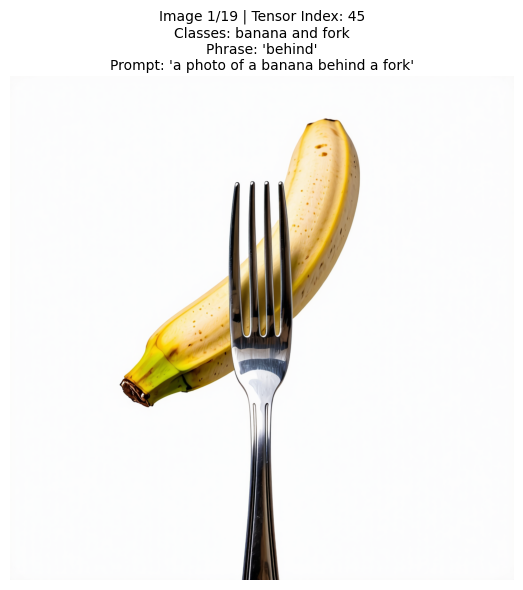

Tensor file: phrase_18989278.pt, Index: 45


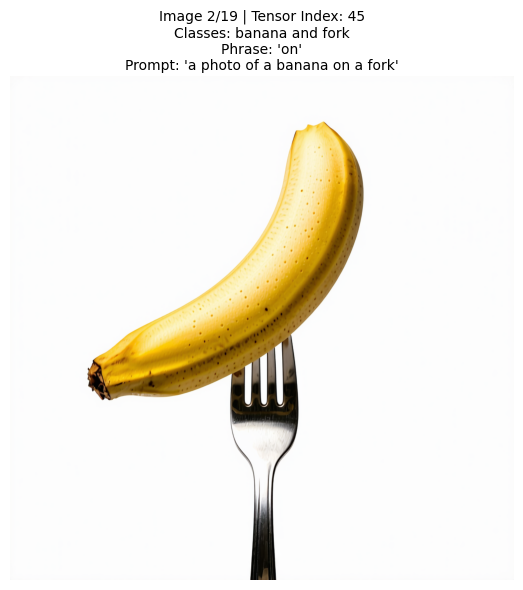

Tensor file: phrase_944229.pt, Index: 45


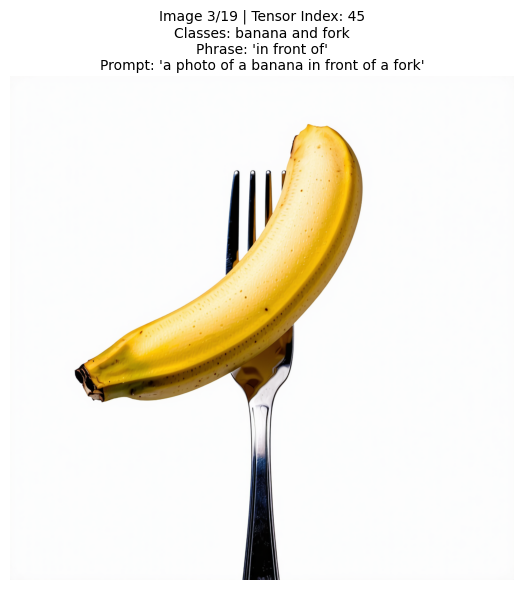

Tensor file: phrase_88935510.pt, Index: 44


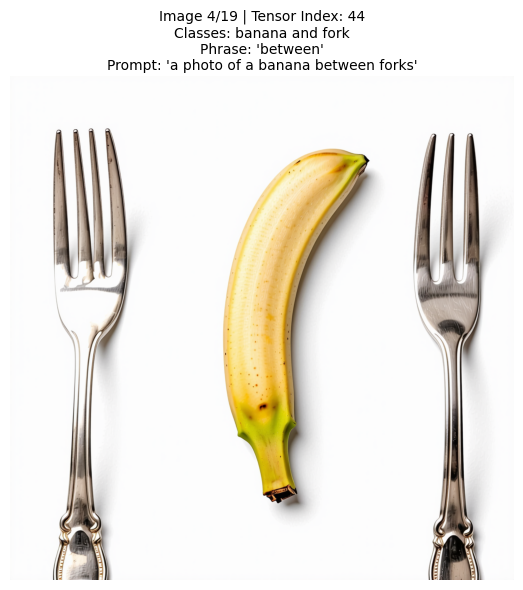

Tensor file: phrase_83844588.pt, Index: 44


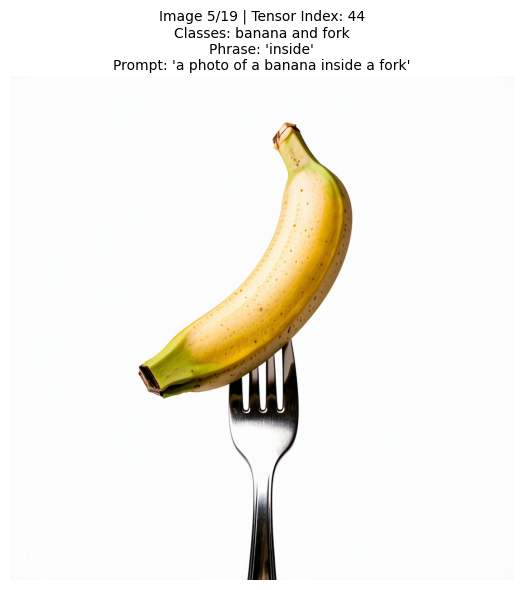

Tensor file: phrase_48784865.pt, Index: 44


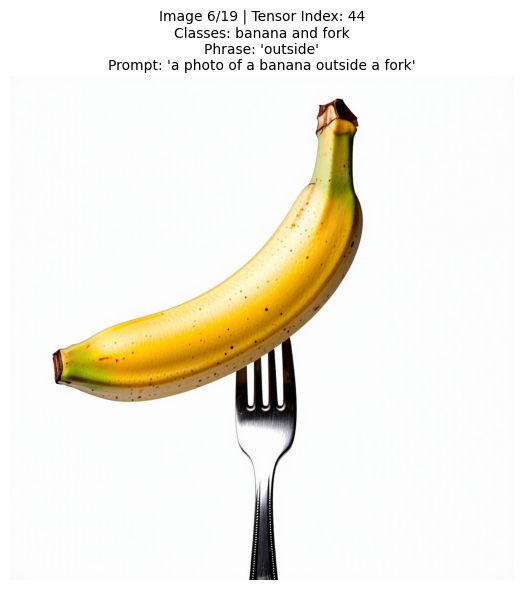

Tensor file: phrase_40680768.pt, Index: 44


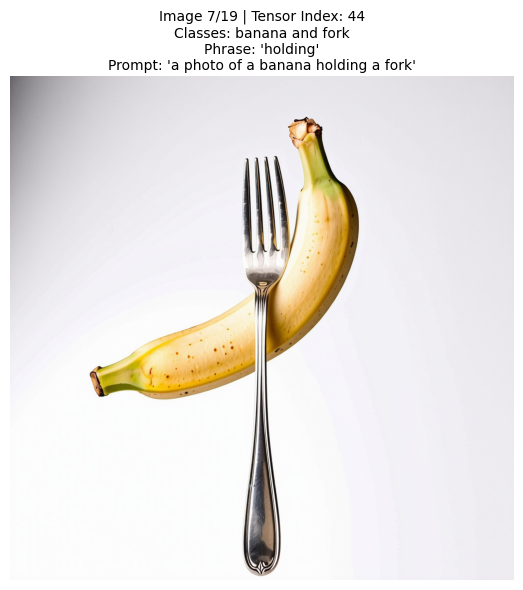

Tensor file: phrase_445283.pt, Index: 44


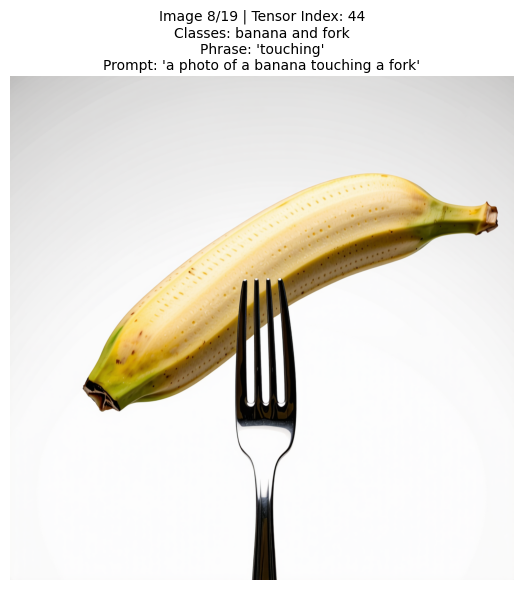

Tensor file: phrase_15252262.pt, Index: 44


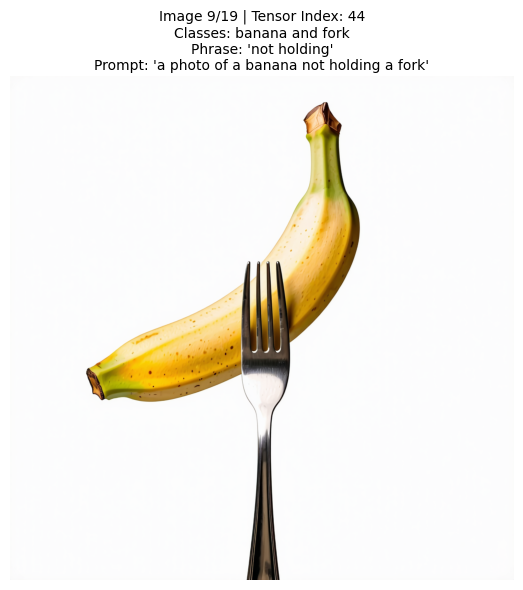

Tensor file: phrase_31985809.pt, Index: 44


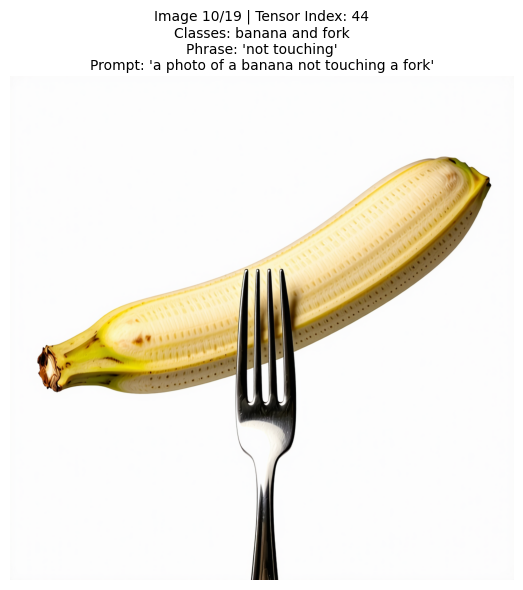

Tensor file: phrase_20730955.pt, Index: 44


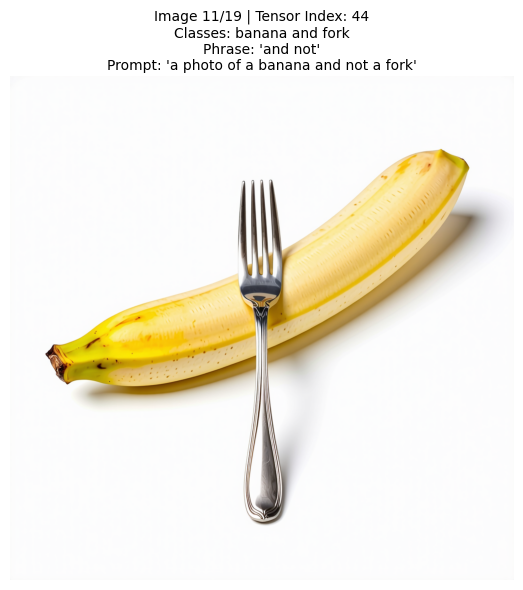

Tensor file: phrase_94410542.pt, Index: 44


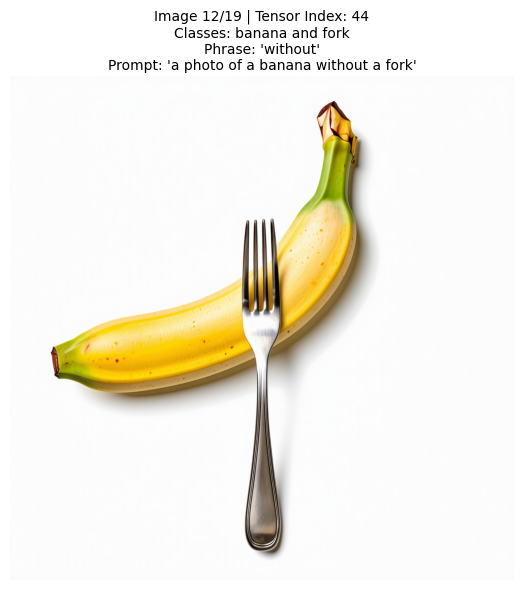

Tensor file: phrase_40502497.pt, Index: 45


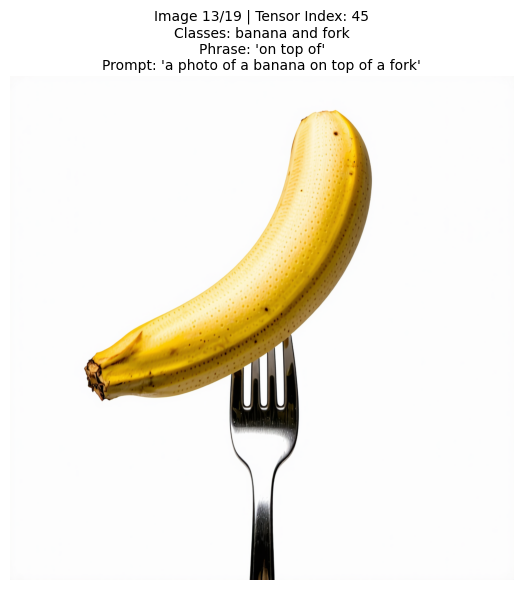

Tensor file: phrase_97999771.pt, Index: 44


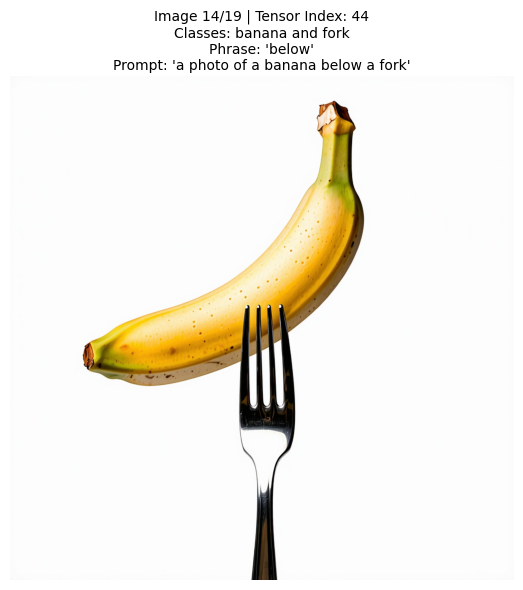

Tensor file: phrase_53123201.pt, Index: 44


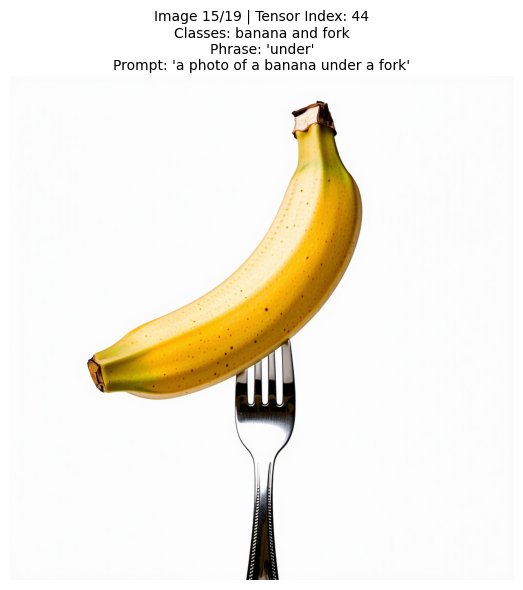

Tensor file: phrase_38486703.pt, Index: 44


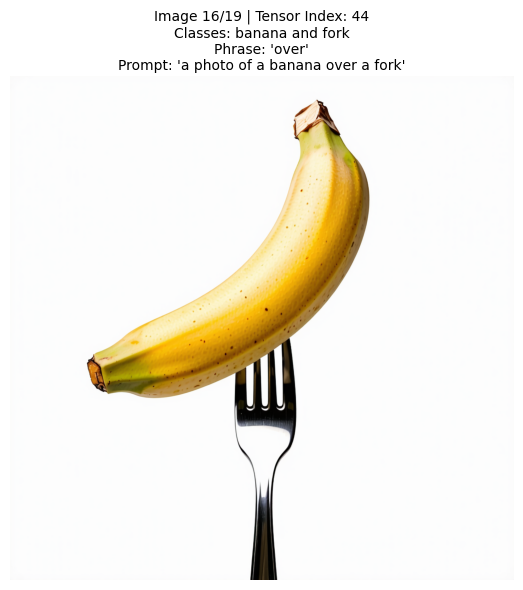

Tensor file: phrase_46534700.pt, Index: 45


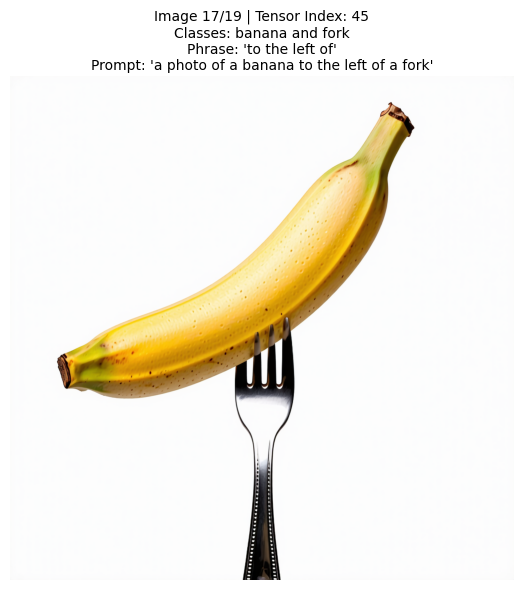

Tensor file: phrase_79660671.pt, Index: 45


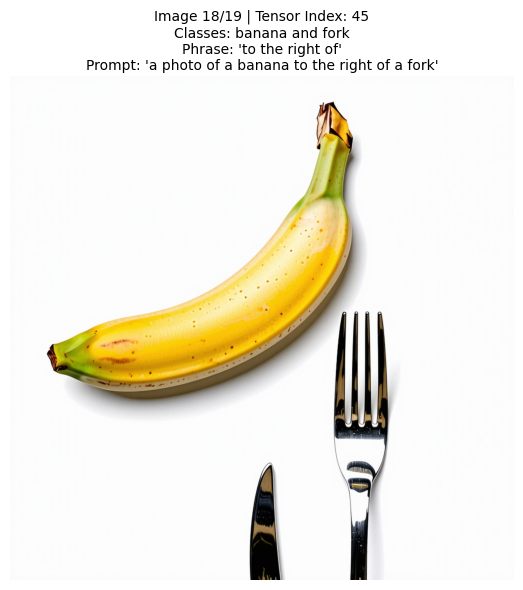

Tensor file: phrase_83840957.pt, Index: 45


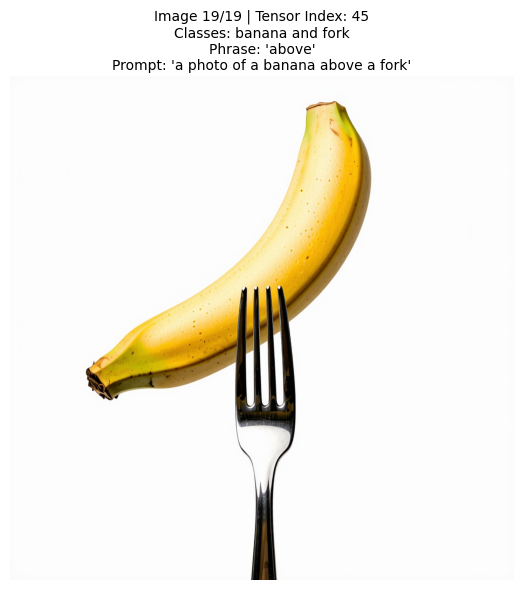

In [15]:

# ===== VISUALIZATION OPTIONS =====
# Choose ONE of the options below and run this cell

# OPTION 1: Visualize by specific CLASSES
CLASS1 = "banana"
CLASS2 = "fork"
PHRASE_FILTER = None  # Set to specific phrase to narrow down, e.g., "behind"
IMAGE_LIMIT = 19

print(f"Visualizing: class1='{CLASS1}' and class2='{CLASS2}'")
if PHRASE_FILTER:
    print(f"Filtered by phrase: '{PHRASE_FILTER}'")

try:
    # Filter by classes
    filtered_df = df_viz[(df_viz['class1'] == CLASS1) & (df_viz['class2'] == CLASS2)]
    
    # Optionally filter by phrase
    if PHRASE_FILTER:
        filtered_df = filtered_df[filtered_df['phrase'] == PHRASE_FILTER]
    
    if filtered_df.empty:
        print(f"❌ NO IMAGES FOUND for class combination '{CLASS1}' and '{CLASS2}'")
        if not PHRASE_FILTER:
            print("\nTry a different class combination. Available options shown above.")
    else:
        print(f"✓ Found {len(filtered_df)} images\n")
        visualize_by_classes(filtered_df, CLASS1, CLASS2, n=IMAGE_LIMIT)
        
except Exception as e:
    print(f"❌ ERROR: {e}")
    import traceback
    traceback.print_exc()


In [17]:
def _slug_for_filename(text):
    """Convert arbitrary text to a filesystem-friendly token."""
    if text is None:
        return "na"
    text = str(text).strip().lower()
    # Keep alnum, convert separators/spaces to single underscores.
    chars = []
    prev_underscore = False
    for ch in text:
        if ch.isalnum():
            chars.append(ch)
            prev_underscore = False
        else:
            if not prev_underscore:
                chars.append("_")
                prev_underscore = True
    slug = "".join(chars).strip("_")
    return slug if slug else "na"


def save_first_n_images_by_model_and_phrase(
    model_name,
    phrase_text,
    n=10,
    output_root="./z7-viz2_outputs",
    prefix_map=None,
    model_dirs_map=None,
    verbose=True,
):
    """
    Save the first n images for a given model + phrase as PNG files.

    Inputs:
      model_name: e.g., 'standard', 'custom_clic', 'cogvlm'
      phrase_text: e.g., 'above'
      n: number of images to save (first n rows after filtering)

    Filename pattern:
      <model_prefix>_<phrase>_<class1>_<class2>_rankXX_tidxY.png
      e.g. sd_above_cat_dog_rank01_tidx3.png
    """
    if prefix_map is None:
        prefix_map = {
            "standard": "sd",
            "sd35": "sd",
            "clic": "clic",
            "custom_clic": "clic",
            "redcaps": "clic",
            "cogvlm": "cogvlm",
        }

    if model_dirs_map is None:
        # Uses directory lists prepared earlier in this notebook.
        model_dirs_map = {
            "standard": sd35_output_dirs,
            "sd35": sd35_output_dirs,
            "custom_clic": custom_clic_output_dirs,
            "clic": custom_clic_output_dirs,
            "redcaps": custom_clic_output_dirs,
            "cogvlm": cogvlm_output_dirs,
        }

    model_key = str(model_name).strip().lower()
    phrase_key = str(phrase_text).strip()

    if model_key not in model_dirs_map:
        raise ValueError(
            f"Unknown model '{model_name}'. Available: {sorted(model_dirs_map.keys())}"
        )

    dirs = model_dirs_map[model_key]
    if not dirs:
        raise ValueError(f"No output directories configured for model '{model_name}'")

    df_model = load_all_metadata(dirs)
    phrase_df = df_model[df_model['phrase'] == phrase_key].copy()

    if phrase_df.empty:
        print(f"No rows found for model='{model_name}' and phrase='{phrase_text}'")
        return []

    os.makedirs(output_root, exist_ok=True)
    model_prefix = prefix_map.get(model_key, _slug_for_filename(model_name))

    saved_files = []
    export_df = phrase_df.head(int(n)).copy()

    if verbose:
        print(
            f"Saving {len(export_df)} image(s) for model='{model_name}', phrase='{phrase_text}' "
            f"to {output_root}"
        )

    for rank, (_, row) in enumerate(export_df.iterrows(), start=1):
        img = get_image_from_tensor(
            row['output_dir'], row['tensor_file'], int(row['tensor_index'])
        )
        if img is None:
            if verbose:
                print(f"Skipping rank {rank}: failed to load tensor image")
            continue

        phrase_slug = _slug_for_filename(row.get('phrase', phrase_text))
        class1_slug = _slug_for_filename(row.get('class1', 'na'))
        class2_slug = _slug_for_filename(row.get('class2', 'na'))
        tensor_idx = int(row.get('tensor_index', -1))

        file_name = (
            f"{model_prefix}_{phrase_slug}_{class1_slug}_{class2_slug}"
            f"_rank{rank:02d}_tidx{tensor_idx}.png"
        )
        save_path = os.path.join(output_root, file_name)
        plt.imsave(save_path, img)
        saved_files.append(save_path)

        if verbose:
            print(f"Saved [{rank}/{len(export_df)}]: {save_path}")

    if verbose:
        print(f"Done. Saved {len(saved_files)} PNG file(s).")

    return saved_files

In [28]:
# # Example usage:
# saved = save_first_n_images_by_model_and_phrase(
#     model_name='clic',
#     phrase_text='to the left of',
#     n=10,
#     output_root="./z7-viz2_outputs",
#     prefix_map=None,  # Use default prefixes
#     model_dirs_map=None,  # Use default directory mapping
#     verbose=True
# )

In [29]:
# models = ['standard', 'clic', 'cogvlm']
# phrases  = ['above', 'below', 'without', 'between', 'to the right of', 'to the left of']
# for model in models:
#     for phrase in phrases:
#         save_first_n_images_by_model_and_phrase(
#             model_name=model,
#             phrase_text=phrase,
#             n=10,
#             output_root="./z7-viz2_outputs",
#             prefix_map=None,  # Use default prefixes
#             model_dirs_map=None,  # Use default directory mapping
#             verbose=True
#         )

In [ ]:
# # Example usage:
# saved = save_first_n_images_by_model_and_phrase(
#     model_name='clic',
#     phrase_text='',
#     n=10,
#     output_root="./z7-viz2_outputs",
#     prefix_map=None,  # Use default prefixes
#     model_dirs_map=None,  # Use default directory mapping
#     verbose=True
# )

Saving 10 image(s) for model='clic', phrase='closeby' to ./z7-viz2_outputs


Saved [1/10]: ./z7-viz2_outputs/clic_closeby_giraffe_hair_drier_rank01_tidx0.png
Saved [2/10]: ./z7-viz2_outputs/clic_closeby_broccoli_skis_rank02_tidx1.png
Saved [3/10]: ./z7-viz2_outputs/clic_closeby_book_sports_ball_rank03_tidx2.png
Saved [4/10]: ./z7-viz2_outputs/clic_closeby_bench_cow_rank04_tidx3.png
Saved [5/10]: ./z7-viz2_outputs/clic_closeby_computer_keyboard_skateboard_rank05_tidx4.png
Saved [6/10]: ./z7-viz2_outputs/clic_closeby_toilet_potted_plant_rank06_tidx5.png
Saved [7/10]: ./z7-viz2_outputs/clic_closeby_oven_vase_rank07_tidx6.png
Saved [8/10]: ./z7-viz2_outputs/clic_closeby_bed_book_rank08_tidx7.png
Saved [9/10]: ./z7-viz2_outputs/clic_closeby_cell_phone_bear_rank09_tidx8.png
Saved [10/10]: ./z7-viz2_outputs/clic_closeby_sports_ball_refrigerator_rank10_tidx9.png
Done. Saved 10 PNG file(s).
